### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** a Bayesian neural network (Pyro) that predicts next-minute humidity with uncertainty bands; plus a deeper Bayesian network for VOC (negative result).

**Data:** the three raw files in `../data/raw/`, resampled to 1-minute means and merged in this notebook (21,016 rows). The saved outputs come from the original run on the same raw CSVs.

**Split:** random 80/20 `train_test_split` (shuffled); the VOC model uses shuffled 5-fold cross-validation. **Horizon:** 1 minute.

**Key result (saved output, standardized units) vs baseline:**

| | R² | MSE | MAE |
|---|---|---|---|
| BNN (3 → 10 → 1), humidity at t+1 | 0.9994 | 0.0006 | 0.0165 |
| Baseline: repeat the last value | 0.9994 | 0.00065 | 0.0163 |

The baseline was computed later, during a review of the project. **The BNN scores the same as simply repeating the last humidity value**, so it shows no forecasting skill. What it does show is how to get credible intervals from a Bayesian model.

VOC with the deeper BNN (64-32-16, lag and rolling features): R² −1.83, −1.61 and −6.91 on the first three folds (worse than predicting the mean). Training was unstable; fold 4 did not finish.

**Caveats**
- Shuffled split and shuffled K-fold on a time series: neighbouring minutes end up in both train and test.
- The StandardScaler is fit on all rows before the split (the VOC model does it correctly inside each fold).
- BNN = persistence (see above). Do not quote R² 0.9994 as a forecasting result.
- Changes during cleanup: one missing line was added in the time-conversion cell (humidity), and the cells after the first BNN were removed (a 60-minute recursive forecast, a full re-run, a shuffled 5-fold run for humidity, and three cells that ended in errors). The VOC experiment is kept at the end.


##### CONTENTS: voc, temperature & humidity Predictions & Forecasting Attempts - Trial & Error Pre-Processing Code

In [3]:
import pandas as pd
import numpy as np 

In [8]:
humidity = pd.read_csv("../data/raw/humidity_raw.csv.gz")
temp = pd.read_csv("../data/raw/temperature_raw.csv.gz")
voc = pd.read_csv("../data/raw/voc_raw.csv.gz")

humidity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373745 entries, 0 to 373744
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   time    373745 non-null  object 
 1   value   373745 non-null  float64
dtypes: float64(1), object(1)
memory usage: 5.7+ MB


In [18]:
temp["time"] = pd.to_datetime(temp["time"],utc=True)
voc["time"] = pd.to_datetime(voc["time"],utc=True)
temp.set_index('time', inplace=True)
voc.set_index('time', inplace=True)

# Added during cleanup: the humidity conversion was in a cell that is missing from the saved notebook
humidity["time"] = pd.to_datetime(humidity["time"], utc=True)
humidity.set_index('time', inplace=True)


In [19]:

# Now resample to 1-minute intervals
humidity_minutely = humidity.resample('1T').mean()
temp_minutely = temp.resample("1T").mean()
voc_minutely = voc.resample("1T").mean()


In [ ]:
#shapes of the data 

print(humidity_minutely.info())
print(temp_minutely.info())
print(voc_minutely.info())


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 21018 entries, 2025-06-03 00:00:00+00:00 to 2025-06-17 14:17:00+00:00
Freq: min
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   21016 non-null  float64
dtypes: float64(1)
memory usage: 328.4 KB
None
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 21018 entries, 2025-06-03 00:00:00+00:00 to 2025-06-17 14:17:00+00:00
Freq: min
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   21016 non-null  float64
dtypes: float64(1)
memory usage: 328.4 KB
None
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 21018 entries, 2025-06-03 00:00:00+00:00 to 2025-06-17 14:17:00+00:00
Freq: min
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   21016 non-null  float64
dtypes: float64(1)
memory usage: 328.4 KB
None


In [26]:
## renaming 

humidity_minutely.rename(columns={'value':'humidity'},inplace=True)
temp_minutely.rename(columns={'value':'temperature'},inplace=True)
voc_minutely.rename(columns={"value":"VOC"},inplace=True)


In [27]:
##concat all of them 
data = pd.concat([humidity_minutely, temp_minutely, voc_minutely], axis=1)
data.head(10)

,humidity,temperature,VOC
time,,,
2025-06-03 00:00:00+00:00,38.809399,23.499704,0.550183
2025-06-03 00:01:00+00:00,38.702040,23.562275,0.566875
2025-06-03 00:02:00+00:00,38.646329,23.608406,0.568810
2025-06-03 00:03:00+00:00,38.702676,23.579998,0.558319
2025-06-03 00:04:00+00:00,38.672044,23.596678,0.557830
2025-06-03 00:05:00+00:00,38.640177,23.623086,0.566260
2025-06-03 00:06:00+00:00,38.623724,23.630687,0.573510
2025-06-03 00:07:00+00:00,38.577087,23.655726,0.558905
2025-06-03 00:08:00+00:00,38.595242,23.648731,0.563025


In [28]:
data.dropna(inplace=True)

In [30]:
import pandas as pd
import numpy as np
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pyro
import pyro.distributions as dist
from pyro.nn import PyroSample, PyroModule
import pyro.infer
from pyro.infer import SVI, Trace_ELBO
from pyro.optim import Adam
import matplotlib.pyplot as plt

# Normalize data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data.dropna())

X = scaled_data[:-1]      # all but last row
y = scaled_data[1:, 0]    # predict sensor1 next value

# Convert to tensors
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)


In [31]:
class BayesianRegression(PyroModule):
    def __init__(self, in_features):
        super().__init__()
        self.fc1 = PyroModule[torch.nn.Linear](in_features, 10)
        self.fc1.weight = PyroSample(dist.Normal(0., 1.).expand([10, in_features]).to_event(2))
        self.fc1.bias = PyroSample(dist.Normal(0., 1.).expand([10]).to_event(1))
        
        self.out = PyroModule[torch.nn.Linear](10, 1)
        self.out.weight = PyroSample(dist.Normal(0., 1.).expand([1, 10]).to_event(2))
        self.out.bias = PyroSample(dist.Normal(0., 1.).expand([1]).to_event(1))

    def forward(self, x, y=None):
        x = torch.relu(self.fc1(x))
        mean = self.out(x).squeeze(-1)
        sigma = pyro.sample("sigma", dist.Uniform(0., 1.))
        with pyro.plate("data", x.shape[0]):
            obs = pyro.sample("obs", dist.Normal(mean, sigma), obs=y)
        return mean


In [32]:
model = BayesianRegression(in_features=X_train.shape[1])
guide = pyro.infer.autoguide.AutoNormal(model)

pyro.clear_param_store()
optimizer = Adam({"lr": 0.01})
svi = SVI(model, guide, optimizer, loss=Trace_ELBO())

# Training loop
num_iterations = 2000
for i in range(num_iterations):
    loss = svi.step(X_train, y_train)
    if i % 100 == 0:
        print(f"[{i}] Loss: {loss:.4f}")


[0] Loss: 41957.4494
[100] Loss: 5889.4392
[200] Loss: 2393.7355
[300] Loss: -6385.4936
[400] Loss: -13272.9912
[500] Loss: -20184.7195
[600] Loss: -26229.3735
[700] Loss: -25778.9996
[800] Loss: -31197.6249
[900] Loss: -32832.3556
[1000] Loss: -35432.8091
[1100] Loss: -33694.3769
[1200] Loss: -36746.7218
[1300] Loss: -34114.5176
[1400] Loss: -27039.3210
[1500] Loss: -34091.5065
[1600] Loss: -33843.3989
[1700] Loss: -36244.6886
[1800] Loss: -36044.1406
[1900] Loss: -36055.9309


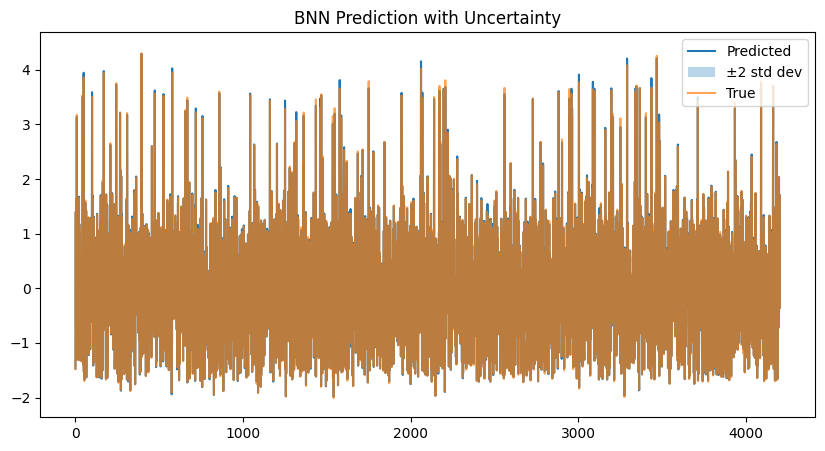

In [33]:
from pyro.infer import Predictive

predictive = Predictive(model, guide=guide, num_samples=1000)
samples = predictive(X_test)
preds = samples["obs"].detach().numpy()

# Calculate mean and std
pred_mean = preds.mean(axis=0)
pred_std = preds.std(axis=0)

# Plot predictions with uncertainty
plt.figure(figsize=(10,5))
plt.plot(pred_mean, label="Predicted")
plt.fill_between(np.arange(len(pred_mean)),
                 pred_mean - 2*pred_std, pred_mean + 2*pred_std,
                 alpha=0.3, label="±2 std dev")
plt.plot(y_test, label="True", alpha=0.7)
plt.legend()
plt.title("BNN Prediction with Uncertainty")
plt.show()


In [34]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Use mean predictions for evaluation
pred_mean = preds.mean(axis=0)

r2 = r2_score(y_test, pred_mean)
mse = mean_squared_error(y_test, pred_mean)
mae = mean_absolute_error(y_test, pred_mean)

print(f"R² Score: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")


R² Score: 0.9994
MSE: 0.0006
MAE: 0.0165



--- Fold 1 ---
Step 0 : loss = 29177.17843180895
Step 100 : loss = 15728.10742944479
Step 200 : loss = 9143.803816854954
Step 300 : loss = 8338.971955776215
Step 400 : loss = 5316.543357491493
Step 500 : loss = -5566.597392320633
Step 600 : loss = -6417.906923890114
Step 700 : loss = -11498.080025076866
Step 800 : loss = -9176.04624402523
Step 900 : loss = -11292.189103722572
Step 1000 : loss = -7133.601602554321
Step 1100 : loss = 6522.029007434845
Step 1200 : loss = -12975.29846227169
Step 1300 : loss = -16290.809724092484
Step 1400 : loss = -18500.853539586067
Step 1500 : loss = 493514.55903172493
Step 1600 : loss = 945065.1620717049
Step 1700 : loss = 169715.94614577293
Step 1800 : loss = 88656.40925908089
Step 1900 : loss = -10805.478869199753
Step 2000 : loss = 34636193.74504864
Step 2100 : loss = 1719.0343290567398
Step 2200 : loss = 15292893.911165714
Step 2300 : loss = -7106.117289185524
Step 2400 : loss = -7025.876188874245
Step 2500 : loss = -3238.2735563516617
Step 2600 : 

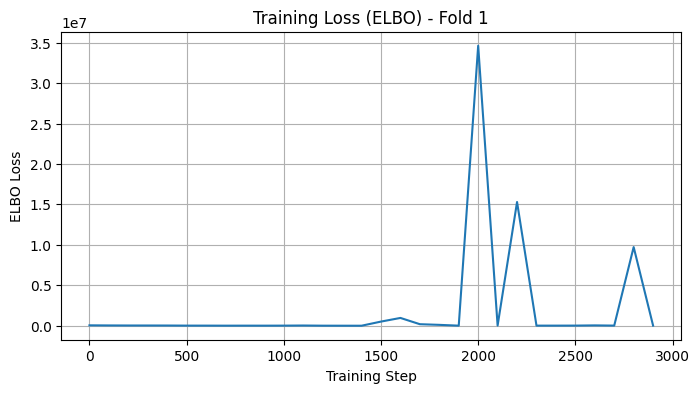

Fold 1 R2: -1.8297


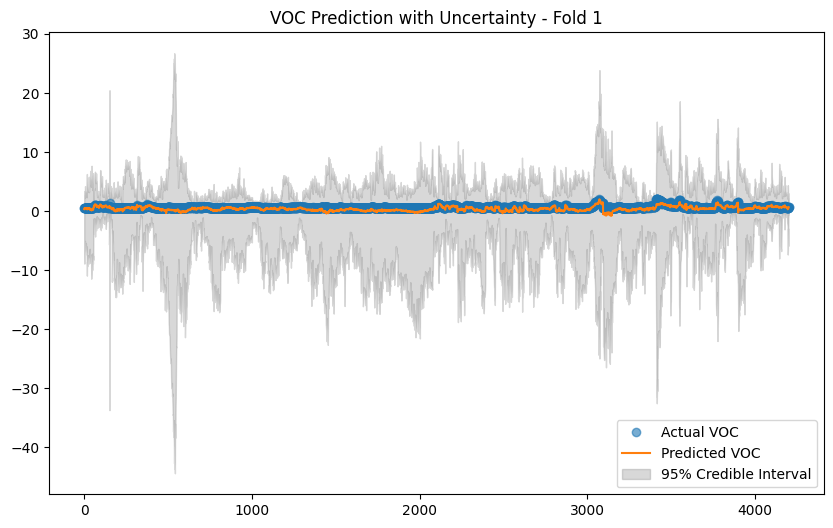


--- Fold 2 ---
Step 0 : loss = 33899.436880886555
Step 100 : loss = 7971.244142413139
Step 200 : loss = 8269.045239150524
Step 300 : loss = -3024.5572704672813
Step 400 : loss = -5290.136289000511
Step 500 : loss = -3694.4836860895157
Step 600 : loss = -6037.642909884453
Step 700 : loss = -6339.653037548065
Step 800 : loss = 2984.237531900406
Step 900 : loss = 10408.527833938599
Step 1000 : loss = -13500.034864664078
Step 1100 : loss = -14017.677924513817
Step 1200 : loss = -14081.031269788742
Step 1300 : loss = -16453.01668739319
Step 1400 : loss = -16260.020238280296
Step 1500 : loss = 33416.241508603096
Step 1600 : loss = 1744.3094136714935
Step 1700 : loss = -8912.213135123253
Step 1800 : loss = 2644296.6704404354
Step 1900 : loss = 20141.76528263092
Step 2000 : loss = -7821.764145255089
Step 2100 : loss = -7753.701413869858
Step 2200 : loss = 2295432.544501424
Step 2300 : loss = 2090574.416872263
Step 2400 : loss = 15829.984985232353
Step 2500 : loss = -1069.395592212677
Step 260

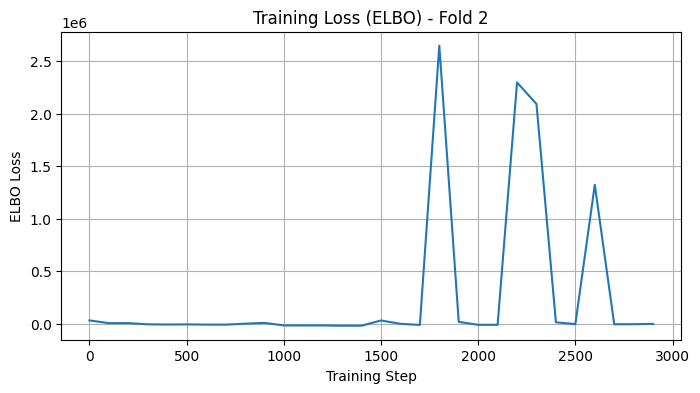

Fold 2 R2: -1.6083


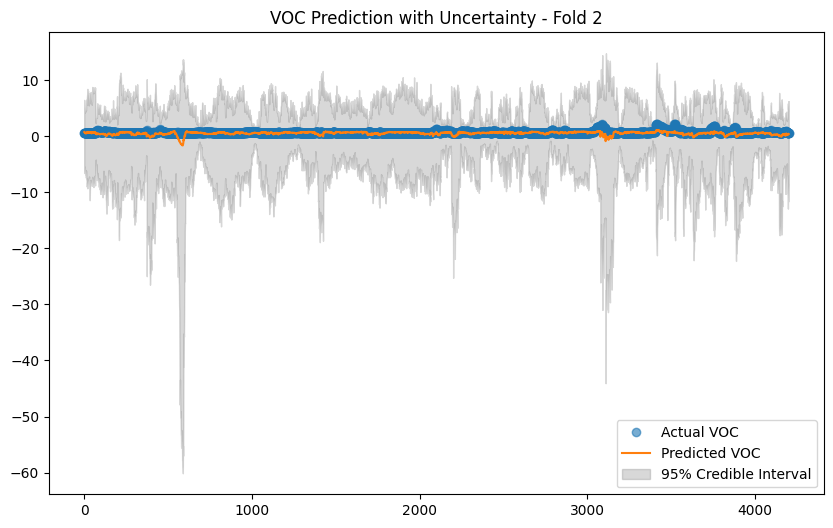


--- Fold 3 ---
Step 0 : loss = 39837.90761452913
Step 100 : loss = 9436.971471488476
Step 200 : loss = 20.476500630378723
Step 300 : loss = -2167.301169514656
Step 400 : loss = 98081.74266457558
Step 500 : loss = 6931.662388563156
Step 600 : loss = -12000.325186252594
Step 700 : loss = -7724.156982541084
Step 800 : loss = -15217.083621382713
Step 900 : loss = -8536.867995262146
Step 1000 : loss = -12275.635964155197
Step 1100 : loss = -12025.030813336372
Step 1200 : loss = -23209.899445950985
Step 1300 : loss = -17941.750883579254
Step 1400 : loss = -12319.685165405273
Step 1500 : loss = 5287.252747178078
Step 1600 : loss = -15012.415427207947
Step 1700 : loss = -16827.85544246435
Step 1800 : loss = -16791.340853631496
Step 1900 : loss = -10054.19184756279
Step 2000 : loss = 150623.5917286873
Step 2100 : loss = -6747.904924035072
Step 2200 : loss = -1546.0127369761467
Step 2300 : loss = 618216.6573967934
Step 2400 : loss = 4212.812630176544
Step 2500 : loss = 826216.5905631781
Step 26

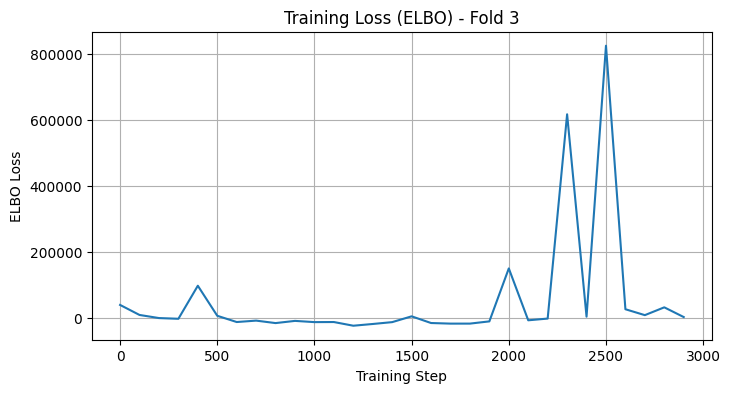

Fold 3 R2: -6.9088


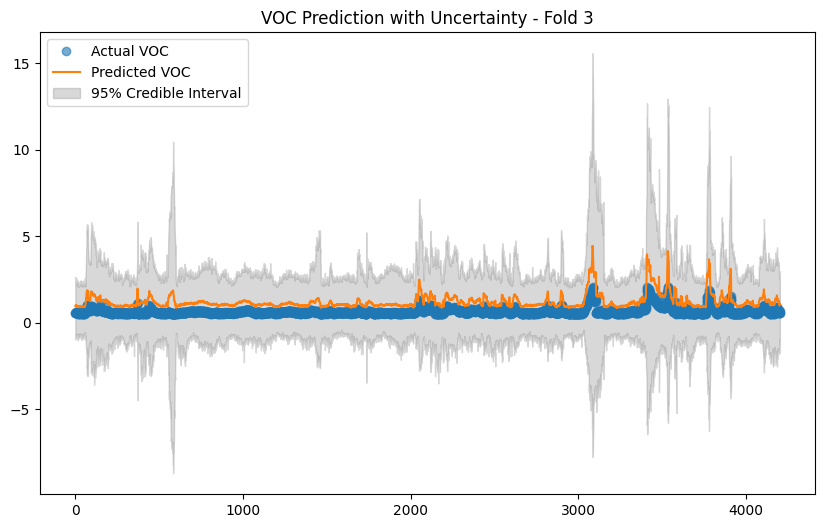


--- Fold 4 ---
Step 0 : loss = 23398.010973751545
Step 100 : loss = 23713.93603205681
Step 200 : loss = 5245.19284081459
Step 300 : loss = 2956.112340927124
Step 400 : loss = 8833.404735088348
Step 500 : loss = -2823.913402199745
Step 600 : loss = -10428.464792966843
Step 700 : loss = -12910.239632844925
Step 800 : loss = -14094.365176558495
Step 900 : loss = -16249.923676609993
Step 1000 : loss = -18104.848101735115
Step 1100 : loss = 25047.857975244522
Step 1200 : loss = 1941.3558223247528
Step 1300 : loss = -9354.75386273861
Step 1400 : loss = -18351.33562707901
Step 1500 : loss = -14542.648510456085
Step 1600 : loss = -10888.611592650414
Step 1700 : loss = 16862.171838760376
Step 1800 : loss = -15513.834809184074
Step 1900 : loss = 199019.11625564098
Step 2000 : loss = -2591.7771441936493
Step 2100 : loss = -8261.319628953934


In [ ]:
import numpy as np
import pandas as pd
import torch
import pyro
import pyro.distributions as dist
from pyro.nn import PyroModule, PyroSample
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# --- Data prep with lags & rolling stats ---
def prepare_features(data):
    # Add lag features
    for lag in range(1, 6):
        data[f'humidity_lag_{lag}'] = data['humidity'].shift(lag)
        data[f'temperature_lag_{lag}'] = data['temperature'].shift(lag)
        data[f'VOC_lag_{lag}'] = data['VOC'].shift(lag)

    # Rolling stats with window=5
    for col in ['humidity', 'temperature', 'VOC']:
        data[f'{col}_roll_mean'] = data[col].rolling(window=5).mean()
        data[f'{col}_roll_std'] = data[col].rolling(window=5).std()

    # Drop rows with NaNs from lagging/rolling
    data.dropna(inplace=True)

    # Cyclic time features from datetime index
    hours = data.index.hour + data.index.minute / 60
    data['time_sin'] = np.sin(2 * np.pi * hours / 24)
    data['time_cos'] = np.cos(2 * np.pi * hours / 24)

    return data

# --- Bayesian regression model with 3 hidden layers ---
class BayesianRegression(PyroModule):
    def __init__(self, in_features):
        super().__init__()
        self.fc1 = PyroModule[torch.nn.Linear](in_features, 64)
        self.fc1.weight = PyroSample(dist.Normal(0., 1.).expand([64, in_features]).to_event(2))
        self.fc1.bias = PyroSample(dist.Normal(0., 1.).expand([64]).to_event(1))
        
        self.fc2 = PyroModule[torch.nn.Linear](64, 32)
        self.fc2.weight = PyroSample(dist.Normal(0., 1.).expand([32, 64]).to_event(2))
        self.fc2.bias = PyroSample(dist.Normal(0., 1.).expand([32]).to_event(1))
        
        self.fc3 = PyroModule[torch.nn.Linear](32, 16)
        self.fc3.weight = PyroSample(dist.Normal(0., 1.).expand([16, 32]).to_event(2))
        self.fc3.bias = PyroSample(dist.Normal(0., 1.).expand([16]).to_event(1))
        
        self.out = PyroModule[torch.nn.Linear](16, 1)
        self.out.weight = PyroSample(dist.Normal(0., 1.).expand([1, 16]).to_event(2))
        self.out.bias = PyroSample(dist.Normal(0., 1.).expand([1]).to_event(1))

    def forward(self, x, y=None):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        mean = self.out(x).squeeze(-1)
        sigma = pyro.sample("sigma", dist.Uniform(0., 1.))
        with pyro.plate("data", x.shape[0]):
            obs = pyro.sample("obs", dist.Normal(mean, sigma), obs=y)
        return mean

# --- Training with LR scheduling ---
def train_bayesian_regression(X_train, y_train, num_steps=3000, lr=0.01, log_interval=100):
    pyro.clear_param_store()
    model = BayesianRegression(in_features=X_train.shape[1])
    guide = pyro.infer.autoguide.AutoNormal(model)
    optimizer = pyro.optim.ClippedAdam({"lr": lr})
    svi = pyro.infer.SVI(model, guide, optimizer, loss=pyro.infer.Trace_ELBO())
    
    X_t = torch.tensor(X_train, dtype=torch.float32)
    y_t = torch.tensor(y_train, dtype=torch.float32)
    
    losses = []
    for step in range(num_steps):
        loss = svi.step(X_t, y_t)
        if step % log_interval == 0:
            print(f"Step {step} : loss = {loss}")
            losses.append(loss)
    return model, guide, losses

# --- Prediction with uncertainty ---
def predict_with_uncertainty(model, guide, X, num_samples=1000):
    model.eval()
    guide.eval()
    predictive = pyro.infer.Predictive(model, guide=guide, num_samples=num_samples)
    X_t = torch.tensor(X, dtype=torch.float32)
    samples = predictive(X_t)
    obs_samples = samples["obs"].detach().numpy()
    
    mean_preds = obs_samples.mean(axis=0)
    lower = np.percentile(obs_samples, 2.5, axis=0)
    upper = np.percentile(obs_samples, 97.5, axis=0)
    return mean_preds, lower, upper

# === Main ===

# Assume 'data' is your DataFrame with datetime index and columns ['humidity', 'temperature', 'VOC']
data = prepare_features(data)

# Features and target
feature_cols = [
    'humidity', 'temperature',
    'time_sin', 'time_cos',
    *[f'humidity_lag_{i}' for i in range(1,6)],
    *[f'temperature_lag_{i}' for i in range(1,6)],
    *[f'VOC_lag_{i}' for i in range(1,6)],
    'humidity_roll_mean', 'humidity_roll_std',
    'temperature_roll_mean', 'temperature_roll_std',
    'VOC_roll_mean', 'VOC_roll_std',
]
target_col = 'VOC'

X_full = data[feature_cols].values
y_full = data[target_col].values

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold = 1

for train_idx, test_idx in kf.split(X_full):
    print(f"\n--- Fold {fold} ---")
    
    X_train_raw, X_test_raw = X_full[train_idx], X_full[test_idx]
    y_train, y_test = y_full[train_idx], y_full[test_idx]
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)
    
    model, guide, losses = train_bayesian_regression(X_train, y_train, num_steps=3000, lr=0.01)
    
    # Plot training loss
    plt.figure(figsize=(8,4))
    plt.plot(np.arange(0, 3000, 100), losses)
    plt.title(f"Training Loss (ELBO) - Fold {fold}")
    plt.xlabel("Training Step")
    plt.ylabel("ELBO Loss")
    plt.grid(True)
    plt.show()
    
    mean_preds, lower, upper = predict_with_uncertainty(model, guide, X_test)
    
    r2 = r2_score(y_test, mean_preds)
    print(f"Fold {fold} R2: {r2:.4f}")
    
    # Plot predictions with credible intervals
    plt.figure(figsize=(10,6))
    plt.plot(y_test, label="Actual VOC", marker='o', linestyle='None', alpha=0.6)
    plt.plot(mean_preds, label="Predicted VOC")
    plt.fill_between(np.arange(len(y_test)), lower, upper, color='gray', alpha=0.3, label="95% Credible Interval")
    plt.title(f"VOC Prediction with Uncertainty - Fold {fold}")
    plt.legend()
    plt.show()
    
    fold += 1
